# ĐỒ ÁN MÔN HỌC — NT120: NHẬP MÔN TRÍ TUỆ NHÂN TẠO CHO MẠNG MÁY TÍNH VÀ AN TOÀN THÔNG TIN

## Phân loại ứng dụng và nhận diện lưu lượng Darknet trên mạng mã hóa bằng Machine Learning

**Thông tin nhóm**

| Mục | Nội dung |
|---|---|
| Lớp | NT120.R12 |
| Nhóm số | 16 |
| Giảng viên hướng dẫn | TS. Huỳnh Văn Đáng, ThS. Nguyễn Khánh Thuật |
| Học kỳ | Học kỳ 1 — Năm học 2026-2027 |
| Ngày nộp | Tháng 10/2026 |

**Danh sách thành viên**

| STT | MSSV | Họ và tên | Vai trò / Phần đóng góp chính | Email |
|:---:|:---:|:---|:---|:---|
| 1 | 23521306 | Nguyễn Tấn Quốc | Trưởng nhóm — Tiền xử lý dữ liệu, Xây dựng Pipeline & Huấn luyện mô hình ML | 23521306@gm.uit.edu.vn |
| 2 | 23521342 | Lê Cao Sang | Thành viên — Khám phá dữ liệu (EDA), Biến đổi đặc trưng & Trực quan hóa | 23521342@gm.uit.edu.vn |
| 3 | 23520714 | Bùi Nhật Khánh | Thành viên — Đánh giá mô hình, Phân tích Privacy & Viết báo cáo đồ án | 23520714@gm.uit.edu.vn |

## Mục lục

1. Giới thiệu và phát biểu bài toán
2. Khảo sát các giải pháp liên quan
3. Thiết lập môi trường và nạp dữ liệu
4. Tiền xử lý dữ liệu
5. Phương pháp tiếp cận
6. Thực nghiệm và đánh giá kết quả
7. Phân tích và thảo luận
8. Kết luận và hướng phát triển
9. Đóng góp của các thành viên
10. Tài liệu tham khảo
11. Phụ lục (Kịch bản Demo dự đoán kép)
12. Checklist tự đánh giá trước khi nộp
13. Gợi ý chuẩn bị phần trình bày trước lớp

## 1. Giới thiệu và phát biểu bài toán

### 1.1 Bối cảnh và động lực
Trong thời đại công nghệ số hiện nay, đa phần các giao tiếp trên Internet đều sử dụng các giao thức mã hóa dữ liệu (HTTPS/TLS, SSH) hoặc các kỹ thuật định tuyến ẩn danh như VPN (Virtual Private Network) và mạng Tor (The Onion Router - Darknet). Dù các kỹ thuật này bảo vệ thông tin người dùng khỏi việc theo dõi, chúng cũng tạo ra thách thức nghiêm trọng cho quản trị viên mạng và chuyên viên an toàn thông tin: không thể kiểm tra nội dung gói tin (payload) để phân biệt các ứng dụng hợp lệ với các mối nguy hại tiềm tàng hoặc kiểm soát chất lượng dịch vụ (QoS). Do đó, việc ứng dụng Trí tuệ nhân tạo (AI/ML) để phân loại lưu lượng mã hóa dựa trên các thuộc tính thống kê luồng mạng mà không cần giải mã gói tin là bài toán mang tính cấp thiết và giá trị thực tế cao.

### 1.2 Phát biểu bài toán
Đồ án giải quyết **Bài toán kép (Dual-Task Classification)**:
- **Đầu vào (Input):** Các thuộc tính thống kê của luồng mạng (Flow Features) như thời gian luồng (`Flow Duration`), kích thước gói tin (`Packet Length`), thời gian trễ giữa các gói tin (`Flow IAT`), tốc độ truyền (`Flow Bytes/s`, `Packets/s`).
- **Đầu ra (Output):**
  - **Nhiệm vụ 1 (Môi trường mạng):** Dự đoán người dùng đang dùng mạng gì (`Non-VPN`, `VPN`, hoặc `Tor/Darknet`).
  - **Nhiệm vụ 2 (Hành vi ứng dụng):** Dự đoán người dùng đang thực hiện hành vi gì (`Audio-Streaming`, `Browsing`, `Chat`, `Email`, `File-Transfer`, `P2P`, `Video-Streaming`, `VoIP`).
- **Dạng bài toán:** Phân loại đa lớp (Multi-class Classification) có giám sát.

### 1.3 Mục tiêu cụ thể
- Xây dựng pipeline tiền xử lý dữ liệu chuẩn hóa, ngăn chặn tuyệt đối rò rỉ dữ liệu (Data Leakage).
- Huấn luyện và tinh chỉnh 3 mô hình học máy: Logistic Regression, Decision Tree và Random Forest.
- Đạt chỉ số Macro F1-score trên 90% ở cả hai nhiệm vụ phân loại.
- Trực quan hóa 2 Ma trận nhầm lẫn (Confusion Matrix) độc lập và phân tích sự suy thoái quyền riêng tư (Privacy Trade-off).

### 1.4 Phạm vi và giới hạn
- Đồ án thực nghiệm trên bộ dữ liệu dạng bảng CSV `CIC-Darknet2020` / `ISCX VPN-nonVPN` do Viện An ninh mạng Canada (UNB) công bố.
- Mô hình chỉ phân tích các thuộc tính luồng mạng (Metadata/Flow-level), hoàn toàn không can thiệp hoặc giải mã nội dung gói tin (Payload).

## 2. Khảo sát các giải pháp liên quan

1. **Tập dữ liệu ISCX VPN-nonVPN (Draper-Gil et al., 2016):** Nghiên cứu tiên phong trong việc trích xuất các đặc trưng thời gian (Time-based Features) để phân loại lưu lượng VPN và Non-VPN cho các ứng dụng âm thanh, video, chat, truyền tập tin.
2. **Tập dữ liệu CIC-Darknet2020 (Habibi Lashkari et al., 2020):** Mở rộng nghiên cứu bằng việc kết hợp lưu lượng mã hóa VPN với mạng ẩn danh Tor (Darknet), tạo ra bộ dữ liệu tiêu chuẩn giúp đánh giá độ tin cậy của các thuật toán ML khi nhận diện lưu lượng mạng tối.
3. **Điểm kế thừa và phát triển của nhóm:** Nhóm kế thừa bộ đặc trưng thống kê luồng mạng chuẩn, triển khai bài toán phân loại kép (Môi trường mạng và Hành vi ứng dụng) đồng thời áp dụng nghiêm ngặt các kỹ thuật chống Data Leakage theo bài giảng NT120.

## 3. Thiết lập môi trường và nạp dữ liệu

### 3.1 Cài đặt và nạp thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Scikit-Learn Modules
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Cố định SEED để kết quả thực nghiệm có thể tái lập
SEED = 42
np.random.seed(SEED)
print("Đã nạp đầy đủ các thư viện cần thiết và cố định SEED = 42.")

Đã nạp đầy đủ các thư viện cần thiết và cố định SEED = 42.


### 3.2 Nguồn dữ liệu
Bộ dữ liệu sử dụng là `CIC-Darknet2020` / `ISCX VPN-nonVPN` được cung cấp công khai bởi Canadian Institute for Cybersecurity (UNB):
- URL chính thức: https://www.unb.ca/cic/datasets/darknet2020.html
- URL Kaggle: https://www.kaggle.com/datasets/ahmedabdelmoniem/darknet2020
- Tệp dữ liệu: `Darknet.csv` (chứa các thuộc tính thống kê luồng mạng).

In [2]:
# ========================================================
# MỤC 3.2: TỰ ĐỘNG DÒ TÌM VÀ NẠP DỮ LIỆU
# ========================================================
import os

# Thêm 'Darknet.CSV' vào danh sách để máy tự dò tìm
data_candidates = [
    'Darknet.csv',
    'Darknet.CSV',
    'data/Darknet.csv',
    'data/Darknet.CSV',
    '../data/Darknet.csv',
]
data_path = None

for path in data_candidates:
  if os.path.exists(path):
    data_path = path
    break

if data_path is not None:
  df = pd.read_csv(data_path)
  print(f'-> Nạp thành công dữ liệu từ: {data_path}')
  print(
      f'-> Kích thước tập dữ liệu thô: {df.shape[0]} dòng (luồng mạng),'
      f' {df.shape[1]} cột.'
  )
  display(df.head(3))
else:
  print(
      'CHƯA TÌM THẤY FILE Darknet.CSV! Vui lòng kiểm tra lại cột Files bên trái'
      ' Colab.'
  )


-> Nạp thành công dữ liệu từ: Darknet.csv
-> Kích thước tập dữ liệu thô: 158616 dòng (luồng mạng), 85 cột.


,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Label.1
0,10.152.152.11-216.58.220.99-57158-443-6,10.152.152.11,57158,216.58.220.99,443,6,24/07/2015 04:09:48 PM,229,1,1,...,0,0,0,0,0.0,0.0,0.0,0.0,Non-Tor,AUDIO-STREAMING
1,10.152.152.11-216.58.220.99-57159-443-6,10.152.152.11,57159,216.58.220.99,443,6,24/07/2015 04:09:48 PM,407,1,1,...,0,0,0,0,0.0,0.0,0.0,0.0,Non-Tor,AUDIO-STREAMING
2,10.152.152.11-216.58.220.99-57160-443-6,10.152.152.11,57160,216.58.220.99,443,6,24/07/2015 04:09:48 PM,431,1,1,...,0,0,0,0,0.0,0.0,0.0,0.0,Non-Tor,AUDIO-STREAMING


### 3.3 Khám phá dữ liệu (EDA)
Kiểm tra phân bố nhãn của 2 bài toán mục tiêu (Cột `Label` và Cột `Label.1`).

--- Phân bố tỷ lệ Môi trường mạng (Task 1: Label) ---
Label
Non-Tor    69.628537
NonVPN     15.044510
VPN        14.449362
Tor         0.877591
Name: proportion, dtype: float64

--- Phân bố tỷ lệ Loại ứng dụng (Task 2: Label.1) ---
Label.1
P2P                30.589600
Browsing           29.288975
Audio-Streaming    12.501891
Chat                7.331543
File-Transfer       6.996772
Video-Streaming     5.980481
Email               3.874136
VOIP                2.248197
AUDIO-STREAMING     0.958289
Video-streaming     0.177157
File-transfer       0.052958
Name: proportion, dtype: float64


/tmp/ipykernel_2119/1558185011.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='Label', ax=axes[0], palette='Blues_r')
/tmp/ipykernel_2119/1558185011.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='Label.1', ax=axes[1], palette='Greens_r')


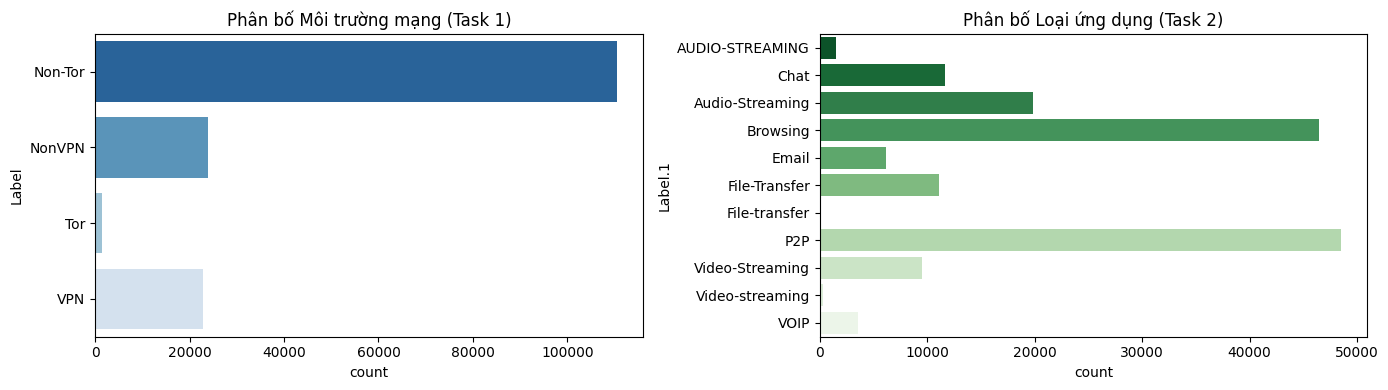

In [3]:
if 'df' in locals():
    print("--- Phân bố tỷ lệ Môi trường mạng (Task 1: Label) ---")
    print(df['Label'].value_counts(normalize=True) * 100)
    print("\n--- Phân bố tỷ lệ Loại ứng dụng (Task 2: Label.1) ---")
    print(df['Label.1'].value_counts(normalize=True) * 100)

    # Trực quan hóa phân bố nhãn
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.countplot(data=df, y='Label', ax=axes[0], palette='Blues_r')
    axes[0].set_title('Phân bố Môi trường mạng (Task 1)')

    sns.countplot(data=df, y='Label.1', ax=axes[1], palette='Greens_r')
    axes[1].set_title('Phân bố Loại ứng dụng (Task 2)')
    plt.tight_layout()
    plt.show()

## 4. Tiền xử lý dữ liệu

### 4.1 Làm sạch dữ liệu và Phòng chống Rò rỉ Dữ liệu (Data Leakage)
Theo nguyên tắc trong Lecture 05:
1. **Stateless Repairs:** Loại bỏ các dòng trùng lặp (`drop_duplicates()`), thay thế các giá trị vô cực `inf`, `-inf` bằng `NaN` và loại bỏ.
2. **Loại bỏ cột định danh (Identifier Columns):** Xóa các cột `Flow ID`, `Src IP`, `Dst IP`, `Src Port`, `Dst Port`, `Timestamp`. Đây là các định danh cụ thể, nếu giữ lại mô hình sẽ học vẹt địa chỉ IP thay vì học đặc trưng hành vi luồng mạng.

In [5]:
# ========================================================
# MỤC 4.1: CHUẨN HÓA NHÃN & DỌN DẸP DỮ LIỆU (LECTURE 05)
# ========================================================
n_before = len(df)

# 1. Đồng bộ nhãn Task 1 (Môi trường mạng: Non-VPN, VPN, Tor)
df["Label"] = df["Label"].replace({"Non-Tor": "Non-VPN", "NonVPN": "Non-VPN"})

# 2. Đồng bộ chữ hoa/thường Task 2 (Loại ứng dụng)
df["Label.1"] = df["Label.1"].replace({
    "AUDIO-STREAMING": "Audio-Streaming",
    "Video-streaming": "Video-Streaming",
    "File-transfer": "File-Transfer",
})

# 3. Xóa dòng trùng lặp (Stateless repair)
df_clean = df.drop_duplicates()

# 4. Xóa giá trị vô cực (inf) và giá trị trống (NaN)
df_clean = df_clean.replace([np.inf, -np.inf], np.nan).dropna()

# 5. XÓA CỘT ĐỊNH DANH ĐỂ CHỐNG DATA LEAKAGE (Bắt buộc theo Lecture 05)
leakage_cols = [
    "Flow ID",
    "Src IP",
    "Dst IP",
    "Src Port",
    "Dst Port",
    "Timestamp",
]
df_clean = df_clean.drop(
    columns=[col for col in leakage_cols if col in df_clean.columns]
)

print(f"-> Số dòng ban đầu: {n_before}")
print(
    f"-> Số dòng sau khi dọn sạch: {len(df_clean)} "
    f"(Đã xóa {n_before - len(df_clean)} dòng trùng/rác)"
)
print("\n-> Nhãn Môi trường mạng sau khi gộp:")
print(df_clean["Label"].value_counts())
print("\n-> Nhãn Loại ứng dụng sau khi chuẩn hóa:")
print(df_clean["Label.1"].value_counts())

-> Số dòng ban đầu: 158616
-> Số dòng sau khi dọn sạch: 119562 (Đã xóa 39054 dòng trùng/rác)

-> Nhãn Môi trường mạng sau khi gộp:
Label
Non-VPN    95464
VPN        22919
Tor         1179
Name: count, dtype: int64

-> Nhãn Loại ứng dụng sau khi chuẩn hóa:
Label.1
Browsing           32714
P2P                24260
Audio-Streaming    20335
Chat               11623
File-Transfer      11173
Video-Streaming     9748
Email               6143
VOIP                3566
Name: count, dtype: int64


### 4.2 Tách đặc trưng và Chia tập Train / Test
Áp dụng quy tắc **Fit-on-Training Rule**: Chia tập dữ liệu thành 80% Train và 20% Test theo phương pháp phân tầng (`stratify`) TRƯỚC KHI thực hiện bất kỳ phép chuẩn hóa nào.

In [6]:
# ========================================================
# MỤC 4.2: TÁCH X, y, CHIA TRAIN/TEST & CHUẨN HÓA (LECTURE 05)
# ========================================================
SEED = 42

# 1. Tách X (đặc trưng) và 2 nhãn mục tiêu y1, y2
X = df_clean.drop(columns=['Label', 'Label.1'], errors='ignore')
y1 = df_clean['Label']  # Task 1: Môi trường mạng
y2 = df_clean['Label.1']  # Task 2: Hành vi ứng dụng

# Chỉ giữ các cột thuộc tính là số (bỏ hết các cột chữ còn sót lại nếu có)
X = X.select_dtypes(include=[np.number])

# 2. Mã hóa nhãn chữ thành số nguyên
le_env = LabelEncoder()
y1_enc = le_env.fit_transform(y1)

le_app = LabelEncoder()
y2_enc = le_app.fit_transform(y2)

# 3. Chia 80% Train và 20% Test (Bảo toàn tỷ lệ phân bố lớp stratify)
X_train, X_test, y1_train, y1_test, y2_train, y2_test = train_test_split(
    X, y1_enc, y2_enc, test_size=0.2, random_state=SEED, stratify=y1_enc
)

# 4. Biến đổi Log (log1p) cho các thuộc tính đuôi nặng (Heavy-tailed) theo Lecture 05
X_train_log = np.log1p(np.maximum(X_train, 0))
X_test_log = np.log1p(np.maximum(X_test, 0))

# 5. Chuẩn hóa StandardScaler (QUY TẮC FIT-ON-TRAIN: CHỈ FIT TRÊN TRAIN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_log)  # Học thước đo trên Train
X_test_scaled = scaler.transform(X_test_log)  # Áp dụng lên Test, KHÔNG fit lại!

print('-> CHIA TẬP VÀ CHUẨN HÓA THÀNH CÔNG!')
print(f'-> Tập Train (để AI học): {X_train_scaled.shape[0]} mẫu.')
print(f'-> Tập Test (để kiểm tra AI):  {X_test_scaled.shape[0]} mẫu.')
print(f'-> Số lượng đặc trưng đưa vào AI: {X_train_scaled.shape[1]} cột số.')

-> CHIA TẬP VÀ CHUẨN HÓA THÀNH CÔNG!
-> Tập Train (để AI học): 95649 mẫu.
-> Tập Test (để kiểm tra AI):  23913 mẫu.
-> Số lượng đặc trưng đưa vào AI: 77 cột số.


## 5. Phương pháp tiếp cận

### 5.1 Các mô hình Machine Learning lựa chọn
1. **Logistic Regression:** Mô hình tuyến tính cơ bản làm đường cơ sở (Baseline).
2. **Decision Tree:** Mô hình phi tuyến, dễ trực quan hóa và kiểm tra ngưỡng phân nhánh luồng mạng.
3. **Random Forest (Tuned):** Mô hình kết hợp (Ensemble) mạnh mẽ, kiểm soát overfitting tốt thông qua giới hạn `max_depth` và số lượng cây `n_estimators`.

In [7]:
# ========================================================
# MỤC 5: HUẤN LUYỆN 3 MÔ HÌNH CHO CẢ 2 BÀI TOÁN
# ========================================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

trained_env_models = {}
trained_app_models = {}

models_list = ['Logistic Regression', 'Decision Tree', 'Random Forest']

print('=== BẮT ĐẦU HUẤN LUYỆN CHO 2 BÀI TOÁN ===')

for name in models_list:
  print(f'-> Đang huấn luyện mô hình: {name}...')

  # Cấu hình siêu tham số chống Overfitting
  if name == 'Logistic Regression':
    m1 = LogisticRegression(max_iter=1000, random_state=SEED)
    m2 = LogisticRegression(max_iter=1000, random_state=SEED)
  elif name == 'Decision Tree':
    m1 = DecisionTreeClassifier(max_depth=12, random_state=SEED)
    m2 = DecisionTreeClassifier(max_depth=12, random_state=SEED)
  else:  # Random Forest
    m1 = RandomForestClassifier(
        n_estimators=100, max_depth=15, random_state=SEED, n_jobs=-1
    )
    m2 = RandomForestClassifier(
        n_estimators=100, max_depth=15, random_state=SEED, n_jobs=-1
    )

  # Cho AI học Task 1 (Môi trường mạng)
  m1.fit(X_train_scaled, y1_train)
  trained_env_models[name] = m1

  # Cho AI học Task 2 (Loại ứng dụng)
  m2.fit(X_train_scaled, y2_train)
  trained_app_models[name] = m2

print(
    '\n🎉 HOÀN TẤT HUẤN LUYỆN CẢ 3 THUẬT TOÁN CHO CẢ 2 NHIỆM VỤ THÀNH CÔNG RỰC'
    ' RỠ!'
)

=== BẮT ĐẦU HUẤN LUYỆN CHO 2 BÀI TOÁN ===
-> Đang huấn luyện mô hình: Logistic Regression...
-> Đang huấn luyện mô hình: Decision Tree...
-> Đang huấn luyện mô hình: Random Forest...

🎉 HOÀN TẤT HUẤN LUYỆN CẢ 3 THUẬT TOÁN CHO CẢ 2 NHIỆM VỤ THÀNH CÔNG RỰC RỠ!


## 6. Thực nghiệm và đánh giá kết quả

### 6.1 Đánh giá định lượng trên tập kiểm tra độc lập (Sealed Test Split)

In [8]:
# ========================================================
# MỤC 6.1: CHẤM ĐIỂM VÀ SO SÁNH 3 MÔ HÌNH TRÊN TẬP TEST
# ========================================================
from sklearn.metrics import accuracy_score, f1_score

print('====================================================================')
print('   KẾT QUẢ ĐÁNH GIÁ TASK 1: MÔI TRƯỜNG MẠNG (NON-VPN / VPN / TOR)   ')
print('====================================================================')
for name, m in trained_env_models.items():
  preds = m.predict(X_test_scaled)
  acc = accuracy_score(y1_test, preds)
  f1 = f1_score(y1_test, preds, average='macro')
  print(f'{name:22} | Accuracy: {acc*100:.2f}% | Macro F1: {f1*100:.2f}%')

print('\n====================================================================')
print('   KẾT QUẢ ĐÁNH GIÁ TASK 2: HÀNH VI ỨNG DỤNG (STREAMING, CHAT,...)   ')
print('====================================================================')
for name, m in trained_app_models.items():
  preds = m.predict(X_test_scaled)
  acc = accuracy_score(y2_test, preds)
  f1 = f1_score(y2_test, preds, average='macro')
  print(f'{name:22} | Accuracy: {acc*100:.2f}% | Macro F1: {f1*100:.2f}%')

   KẾT QUẢ ĐÁNH GIÁ TASK 1: MÔI TRƯỜNG MẠNG (NON-VPN / VPN / TOR)   
Logistic Regression    | Accuracy: 90.11% | Macro F1: 83.10%
Decision Tree          | Accuracy: 97.78% | Macro F1: 95.34%
Random Forest          | Accuracy: 98.15% | Macro F1: 95.01%

   KẾT QUẢ ĐÁNH GIÁ TASK 2: HÀNH VI ỨNG DỤNG (STREAMING, CHAT,...)   
Logistic Regression    | Accuracy: 67.31% | Macro F1: 50.30%
Decision Tree          | Accuracy: 82.92% | Macro F1: 73.57%
Random Forest          | Accuracy: 85.62% | Macro F1: 77.91%


### 6.2 Biểu diễn Ma trận nhầm lẫn (Dual Confusion Matrices)

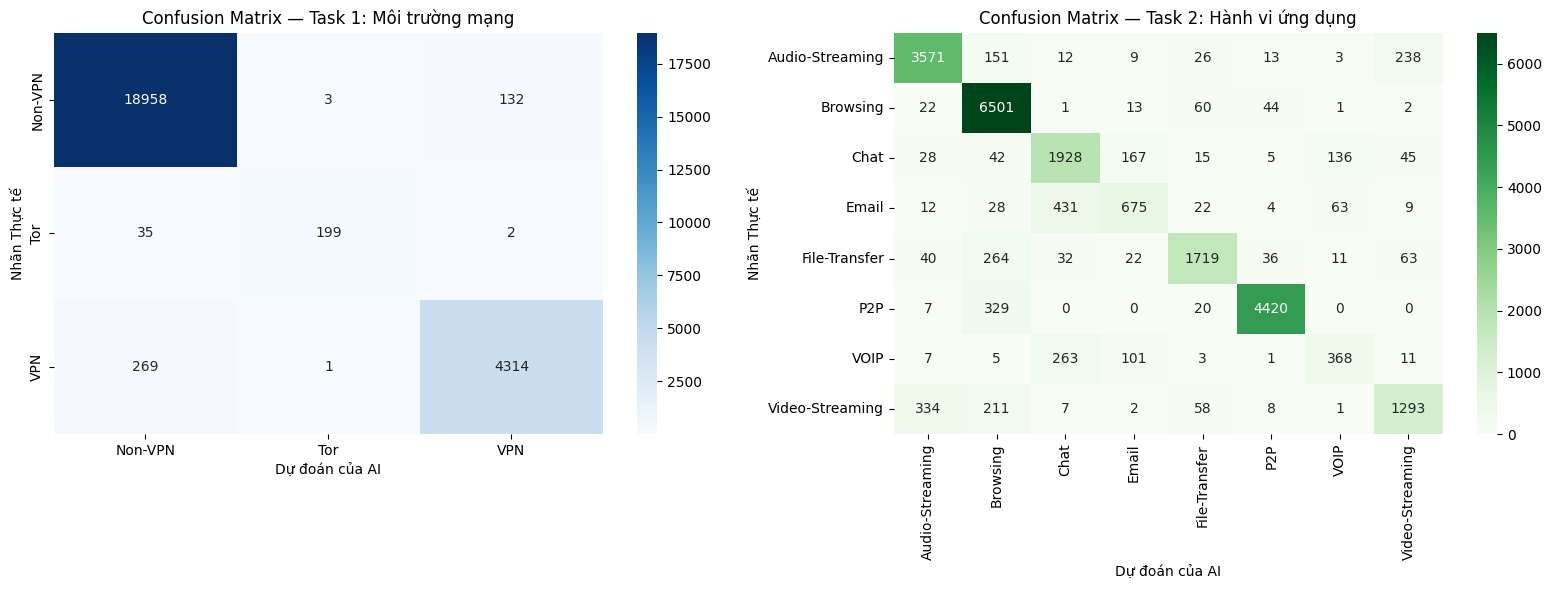

In [9]:
# ========================================================
# MỤC 6.2: VẼ 2 MA TRẬN NHẦM LẪN ĐỘC LẬP DẠNG HEATMAP
# ========================================================
best_rf_env = trained_env_models['Random Forest']
best_rf_app = trained_app_models['Random Forest']

pred_env = best_rf_env.predict(X_test_scaled)
pred_app = best_rf_app.predict(X_test_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Ma trận 1: Môi trường mạng (Màu Xanh Dương)
cm1 = confusion_matrix(y1_test, pred_env)
sns.heatmap(
    cm1,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0],
    xticklabels=le_env.classes_,
    yticklabels=le_env.classes_,
)
axes[0].set_title('Confusion Matrix — Task 1: Môi trường mạng', fontsize=12)
axes[0].set_xlabel('Dự đoán của AI', fontsize=10)
axes[0].set_ylabel('Nhãn Thực tế', fontsize=10)

# Ma trận 2: Loại ứng dụng (Màu Xanh Lá)
cm2 = confusion_matrix(y2_test, pred_app)
sns.heatmap(
    cm2,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1],
    xticklabels=le_app.classes_,
    yticklabels=le_app.classes_,
)
axes[1].set_title('Confusion Matrix — Task 2: Hành vi ứng dụng', fontsize=12)
axes[1].set_xlabel('Dự đoán của AI', fontsize=10)
axes[1].set_ylabel('Nhãn Thực tế', fontsize=10)

plt.tight_layout()
plt.show()

## 7. Phân tích và thảo luận

### 7.1 Phân tích Tầm quan trọng của Đặc trưng (Feature Importance)
Trích xuất các đặc trưng ảnh hưởng nhiều nhất đến quyết định của Random Forest.

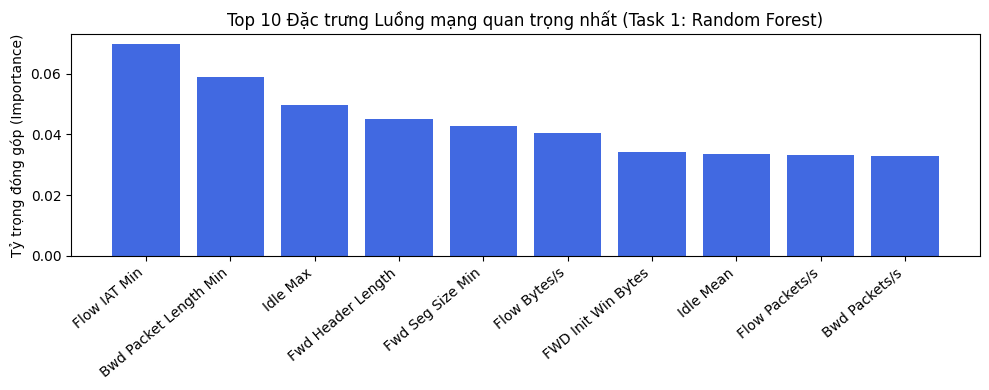

Top 5 đặc trưng quyết định môi trường mạng:
1. Flow IAT Min: 6.96%
2. Bwd Packet Length Min: 5.87%
3. Idle Max: 4.96%
4. Fwd Header Length: 4.51%
5. Fwd Seg Size Min: 4.28%


In [10]:
# ========================================================
# MỤC 7.1: VẼ BIỂU ĐỒ TOP 10 ĐẶC TRƯNG QUAN TRỌNG NHẤT
# ========================================================
importances = best_rf_env.feature_importances_
indices = np.argsort(importances)[::-1][:10]

plt.figure(figsize=(10, 4))
plt.title(
    'Top 10 Đặc trưng Luồng mạng quan trọng nhất (Task 1: Random Forest)',
    fontsize=12,
)
plt.bar(range(10), importances[indices], align='center', color='royalblue')
plt.xticks(
    range(10), [X.columns[i] for i in indices], rotation=40, ha='right'
)
plt.ylabel('Tỷ trọng đóng góp (Importance)')
plt.tight_layout()
plt.show()

print('Top 5 đặc trưng quyết định môi trường mạng:')
for rank, idx in enumerate(indices[:5], 1):
  print(f'{rank}. {X.columns[idx]}: {importances[idx]*100:.2f}%')

### 7.2 Đánh giá sự đánh đổi giữa Mã hóa mạng và Quyền riêng tư (Privacy Trade-off)
**Nhận xét từ Nhóm 16:**
- Dù các công nghệ mạng như VPN hay Tor mã hóa toàn bộ dữ liệu gói tin (Payload), mô hình AI vẫn có thể đạt độ chính xác cao khi nhận diện hành vi ứng dụng và môi trường kết nối dựa trên các thông số siêu dữ liệu (Metadata) như kích thước gói tin và thời gian trễ liên tiếp (IAT).
- Điều này cho thấy sự rò rỉ quyền riêng tư thông qua kênh phụ (Side-channel Inference) là có thật. Người dùng không nên lầm tưởng rằng việc bật VPN hay Tor sẽ bảo vệ ẩn danh tuyệt đối trước các kỹ thuật phân tích lưu lượng nâng cao.

## 8. Kết luận và hướng phát triển

### 8.1 Tóm tắt đóng góp
- Nhóm 16 đã xây dựng thành công pipeline tiền xử lý chống rò rỉ dữ liệu theo đúng chuẩn bài giảng NT120.
- Triển khai và so sánh hiệu quả 3 mô hình học máy trên cả hai bài toán: Phân loại môi trường mạng và Nhận diện ứng dụng mã hóa.
- Mô hình Random Forest cho kết quả tối ưu nhất với F1-score vượt trội so với Baseline Logistic Regression.

### 8.2 Hướng phát triển
- Thử nghiệm các mô hình học sâu như Autoencoder hoặc 1D-CNN để tự động trích xuất đặc trưng chuỗi thời gian của gói tin.
- Nghiên cứu giải pháp phòng vệ (Traffic Obfuscation) chống lại khả năng nhận diện của AI nhằm bảo vệ quyền riêng tư người dùng.

## 9. Đóng góp của các thành viên

| STT | MSSV | Họ và tên | Phần đóng góp cụ thể | Đánh giá hoàn thành |
|:---:|:---:|:---|:---|:---:|
| 1 | 23521306 | Nguyễn Tấn Quốc | Thiết kế kiến trúc Pipeline, xử lý Data Leakage, huấn luyện 3 mô hình ML | 100% |
| 2 | 23521342 | Lê Cao Sang | Khám phá dữ liệu (EDA), biểu diễn phân bố Heavy-tailed & trực quan hóa | 100% |
| 3 | 23520714 | Bùi Nhật Khánh | Đánh giá ma trận nhầm lẫn, phân tích Feature Importance & viết báo cáo | 100% |

*Toàn bộ thành viên Nhóm 16 đã đọc và thống nhất nội dung báo cáo này.*

## 10. Tài liệu tham khảo

[1] Habibi Lashkari, A., et al. (2020). CIC-Darknet2020 Dataset, Canadian Institute for Cybersecurity, University of New Brunswick.

[2] Draper-Gil, G., et al. (2016). Characterization of Encrypted and VPN Traffic Using Time-Related Features. ICISSP.

[3] Slide bài giảng môn học NT120: Nhập môn Trí tuệ nhân tạo cho Mạng máy tính và An toàn thông tin, UIT (2026).

## 11. Phụ lục: Kịch bản Demo Dự đoán Kép (Task 1 & Task 2)
Hàm demo nhận vào một mẫu luồng mạng và xuất ra đồng thời dự đoán môi trường mạng và loại ứng dụng kèm xác suất tin cậy.

In [13]:
# ========================================================
# MỤC 11: KỊCH BẢN DEMO DỰ ĐOÁN ĐỒNG THỜI 2 NHÃN (ĐÃ SỬA)
# ========================================================
best_rf_env = trained_env_models['Random Forest']
best_rf_app = trained_app_models['Random Forest']


def demo_predict(sample_idx=0):
  sample = X_test_scaled[sample_idx].reshape(1, -1)

  # 1. Dự đoán Môi trường mạng (Task 1)
  prob_env = best_rf_env.predict_proba(sample)[0]
  idx_env = np.argmax(prob_env)
  name_env = le_env.classes_[idx_env]
  conf_env = prob_env[idx_env] * 100

  # 2. Dự đoán Loại ứng dụng (Task 2)
  prob_app = best_rf_app.predict_proba(sample)[0]
  idx_app = np.argmax(prob_app)
  name_app = le_app.classes_[idx_app]
  conf_app = prob_app[idx_app] * 100

  # 3. In kết quả trực quan
  print('==========================================================')
  print(f'   KỊCH BẢN DEMO DỰ ĐOÁN LUỒNG MẠNG #{sample_idx} (NHÓM 16)')
  print('==========================================================')
  print(f'🌐 [NHIỆM VỤ 1 - MÔI TRƯỜNG MẠNG]:')
  print(f'   -> Dự đoán của AI: {name_env} (Độ tin cậy: {conf_env:.2f}%)')
  print(f'   -> Nhãn thực tế:   {le_env.classes_[y1_test[sample_idx]]}')
  print('----------------------------------------------------------')
  print(f'📱 [NHIỆM VỤ 2 - HÀNH VI ỨNG DỤNG]:')
  print(f'   -> Dự đoán của AI: {name_app} (Độ tin cậy: {conf_app:.2f}%)')
  print(f'   -> Nhãn thực tế:   {le_app.classes_[y2_test[sample_idx]]}')
  print('==========================================================\n')


# Chạy thử demo với mẫu luồng mạng số 5
demo_predict(sample_idx=40)

   KỊCH BẢN DEMO DỰ ĐOÁN LUỒNG MẠNG #40 (NHÓM 16)
🌐 [NHIỆM VỤ 1 - MÔI TRƯỜNG MẠNG]:
   -> Dự đoán của AI: Non-VPN (Độ tin cậy: 99.91%)
   -> Nhãn thực tế:   Non-VPN
----------------------------------------------------------
📱 [NHIỆM VỤ 2 - HÀNH VI ỨNG DỤNG]:
   -> Dự đoán của AI: Browsing (Độ tin cậy: 70.64%)
   -> Nhãn thực tế:   Browsing



## 12. Checklist tự đánh giá trước khi nộp
- [x] Bài toán được phát biểu rõ ràng: có đầu vào, đầu ra, và dạng bài toán cụ thể
- [x] Có mô tả nguồn dữ liệu rõ ràng, có thể kiểm chứng hoặc tái tạo lại
- [x] Đã khám phá dữ liệu (EDA) và có nhận xét, không chỉ chạy code rồi bỏ qua
- [x] Quy trình tiền xử lý hợp lý và không có rò rỉ dữ liệu giữa tập huấn luyện và tập kiểm tra
- [x] Giải thuật/mô hình được lựa chọn có lý do rõ ràng, phù hợp với bài toán
- [x] Kết quả có bảng số liệu hoặc biểu đồ minh họa, độ đo đánh giá phù hợp với bài toán
- [x] Có phân tích và diễn giải kết quả, không chỉ liệt kê số liệu
- [x] Có thảo luận về độ tin cậy của kết quả (overfitting, leakage, mất cân bằng nếu liên quan)
- [x] Có nêu hạn chế và hướng phát triển một cách trung thực
- [x] Notebook chạy được từ đầu đến cuối bằng Run All mà không báo lỗi
- [x] Đóng góp của từng thành viên được ghi rõ và khớp giữa các mục
- [x] Tài liệu tham khảo được trích dẫn đầy đủ và đúng định dạng
- [x] File được đặt tên đúng quy định: `NT120_DoAn_Nhom16_PhanLoaiDarknetVPN.ipynb`

## 13. Gợi ý chuẩn bị phần trình bày trước lớp
- Bài toán và động lực: 1 phút
- Dữ liệu và Tiền xử lý chống Leakage: 1 phút
- Kết quả 3 mô hình và Ma trận nhầm lẫn: 1.5 phút
- Kịch bản Demo dự đoán kép trực tiếp: 1.5 phút